# Checkpoint EDA — Heat & Energy Burden

**ผู้รับผิดชอบ:** บูรพา จินดาเลิศ (Burapa Jindaloet)  
**รายวิชา:** CS341 Big Data Engineering  
**Project:** Urban Heat & Energy Burden

Notebook นี้ทำ Exploratory Data Analysis (EDA) จากข้อมูลที่ผ่านการ Validate/Clean แล้วใน Silver Zone ได้แก่

- `clean_temperature.parquet` — อุณหภูมิเฉลี่ยรายวัน
- `clean_electricity.parquet` — ปริมาณการใช้ไฟฟ้าระดับเขต/ปี

> **ขอบเขตและข้อจำกัด:** ณ เวลาที่ตรวจ Repository มีไฟล์ Parquet อยู่ใน `data/silver/` แต่ `data/gold/` ยังไม่มี Curated Parquet และ Notebook นี้จึงเริ่มจาก Silver Zone ก่อน ข้อมูลที่มีอยู่ยังไม่มีวัสดุหลังคา การระบายอากาศ ร่มเงา รายได้ครัวเรือน หรือค่าใช้จ่ายพลังงานรายครัวเรือน ดังนั้นยังไม่สามารถตอบ Q1/Q2 ในระดับครัวเรือนได้โดยตรง ห้ามตีความผลระดับปี/เขตเป็นความสัมพันธ์เชิงเหตุและผล


## 1. Environment และการตั้งค่า

ติดตั้ง dependencies ด้วย `pip install -r requirements.txt` จาก root ของ Repository แล้วเปิด Notebook จากโฟลเดอร์ `notebooks/` หรือ root ก็ได้


In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import duckdb
from IPython.display import display

# รองรับทั้งการเปิด Jupyter จาก root และจาก notebooks/
HERE = Path.cwd()
if (HERE / "data").exists():
    PROJECT_ROOT = HERE
elif (HERE.parent / "data").exists():
    PROJECT_ROOT = HERE.parent
else:
    raise FileNotFoundError(
        "ไม่พบโฟลเดอร์ data/ กรุณาเปิด Notebook ภายใน Repository นี้"
    )

SILVER_DIR = PROJECT_ROOT / "data" / "silver"
GOLD_DIR = PROJECT_ROOT / "data" / "gold"

TEMP_PATH = SILVER_DIR / "clean_temperature.parquet"
ELEC_PATH = SILVER_DIR / "clean_electricity.parquet"

print("Project root:", PROJECT_ROOT)
print("Temperature file:", TEMP_PATH.exists())
print("Electricity file:", ELEC_PATH.exists())
print("Gold parquet files:", list(GOLD_DIR.glob("*.parquet")) if GOLD_DIR.exists() else [])


Project root: C:\Users\User\urban-heat-energy-burden
Temperature file: True
Electricity file: True
Gold parquet files: [WindowsPath('C:/Users/User/urban-heat-energy-burden/data/gold/agg_temperature_monthly.parquet'), WindowsPath('C:/Users/User/urban-heat-energy-burden/data/gold/agg_temperature_yearly.parquet'), WindowsPath('C:/Users/User/urban-heat-energy-burden/data/gold/agg_year_energy_heat.parquet'), WindowsPath('C:/Users/User/urban-heat-energy-burden/data/gold/dim_district.parquet'), WindowsPath('C:/Users/User/urban-heat-energy-burden/data/gold/fact_district_energy_heat_yearly.parquet')]


## 2. Load data จาก Silver Zone

Notebook นี้ไม่อ่าน CSV ดิบซ้ำ แต่ใช้ผลลัพธ์ที่ผ่านสคริปต์ `scripts/02_validate_clean.py` แล้ว


In [3]:
if not TEMP_PATH.exists():
    raise FileNotFoundError(
        "ไม่พบ data/silver/clean_temperature.parquet "
        "โปรดรัน python scripts/02_validate_clean.py ก่อน"
    )

if not ELEC_PATH.exists():
    raise FileNotFoundError(
        "ไม่พบ data/silver/clean_electricity.parquet "
        "โปรดรัน python scripts/02_validate_clean.py ก่อน"
    )

temperature = pd.read_parquet(TEMP_PATH)
electricity = pd.read_parquet(ELEC_PATH)

print(f"Temperature: {temperature.shape[0]:,} rows × {temperature.shape[1]} columns")
print(f"Electricity: {electricity.shape[0]:,} rows × {electricity.shape[1]} columns")

display(temperature.head())
display(electricity.head())


Temperature: 3,964 rows × 4 columns
Electricity: 180 rows × 3 columns


,date,avg_temp,year,month
0,2016-01-01,25.4,2016,1
1,2016-01-02,25.7,2016,1
2,2016-01-03,26.4,2016,1
3,2016-01-04,27.2,2016,1
4,2016-01-05,27.4,2016,1


,year,district,consumption_million_kwh
0,2016,วัดเลียบ,1125.20
1,2017,วัดเลียบ,1105.84
2,2018,วัดเลียบ,1098.84
3,2019,วัดเลียบ,1191.83
4,2020,วัดเลียบ,1054.94


## 3. Dataset overview และ Data types

ดู schema, จำนวนแถว, missing values และจำนวนค่าที่ไม่ซ้ำของแต่ละคอลัมน์


In [3]:
def dataset_overview(df: pd.DataFrame, name: str) -> pd.DataFrame:
    summary = pd.DataFrame({
        "column": df.columns,
        "dtype": [str(dtype) for dtype in df.dtypes],
        "non_null": [int(df[col].notna().sum()) for col in df.columns],
        "missing": [int(df[col].isna().sum()) for col in df.columns],
        "unique": [int(df[col].nunique(dropna=True)) for col in df.columns],
    })
    print(f"{name}: {len(df):,} rows")
    display(summary)
    return summary

temperature_overview = dataset_overview(temperature, "Temperature")
electricity_overview = dataset_overview(electricity, "MEA electricity")


Temperature: 3,964 rows


,column,dtype,non_null,missing,unique
0,date,str,3964,0,3964
1,avg_temp,float64,3964,0,130
2,year,int64,3964,0,11
3,month,int64,3964,0,12


MEA electricity: 180 rows


,column,dtype,non_null,missing,unique
0,year,int64,180,0,10
1,district,str,180,0,18
2,consumption_million_kwh,float64,180,0,180


## 4. Missing values และ Duplicate checks

ตรวจสอบคุณภาพข้อมูลซ้ำอีกครั้งในมุม EDA แม้ทีมจะมี Validation ใน Silver pipeline แล้ว


In [4]:
def quality_summary(df: pd.DataFrame, name: str) -> None:
    print(f"--- {name} ---")
    print("Duplicate rows:", int(df.duplicated().sum()))

    missing = df.isna().sum().to_frame("missing_count")
    missing["missing_pct"] = (
        missing["missing_count"] / max(len(df), 1) * 100
    ).round(2)
    display(missing)

quality_summary(temperature, "Temperature")
quality_summary(electricity, "Electricity")


--- Temperature ---
Duplicate rows: 0


,missing_count,missing_pct
date,0,0.0
avg_temp,0,0.0
year,0,0.0
month,0,0.0


--- Electricity ---
Duplicate rows: 0


,missing_count,missing_pct
year,0,0.0
district,0,0.0
consumption_million_kwh,0,0.0


## 5. Descriptive statistics และ Distribution

แสดงสถิติพื้นฐานและ histogram เพื่อดูการกระจายตัวของอุณหภูมิและการใช้ไฟฟ้า


,count,mean,std,min,25%,50%,75%,max
avg_temp,3964.0,28.151261,1.779404,17.2,27.2,28.1,29.2,33.3


,count,mean,std,min,25%,50%,75%,max
consumption_million_kwh,180.0,2911.289833,1153.477897,942.03,1967.5575,2645.5,3683.8125,5538.93


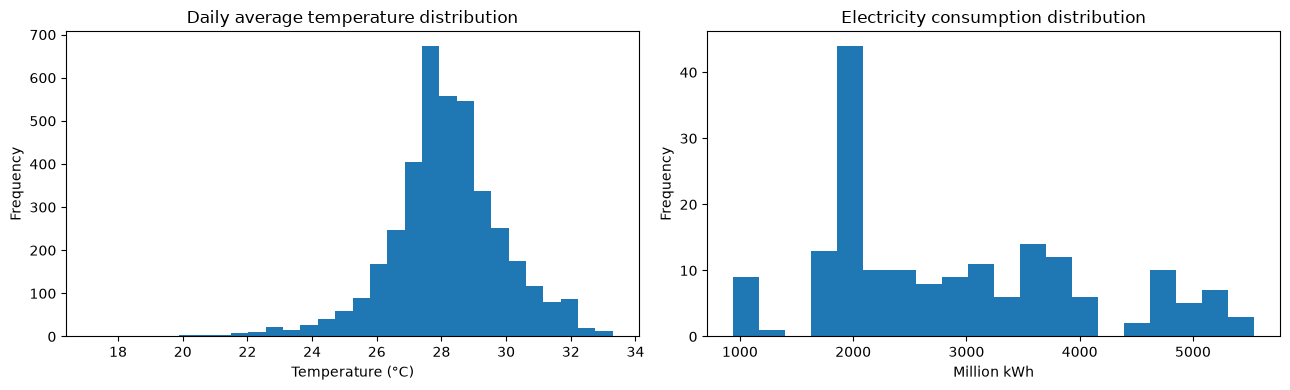

In [5]:
display(temperature[["avg_temp"]].describe().T)
display(electricity[["consumption_million_kwh"]].describe().T)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(temperature["avg_temp"].dropna(), bins=30)
axes[0].set_title("Daily average temperature distribution")
axes[0].set_xlabel("Temperature (°C)")
axes[0].set_ylabel("Frequency")

axes[1].hist(electricity["consumption_million_kwh"].dropna(), bins=20)
axes[1].set_title("Electricity consumption distribution")
axes[1].set_xlabel("Million kWh")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()


## 6. Temperature trend — Monthly และ Yearly

อุณหภูมิเป็นข้อมูลรายวัน จึงสรุปเป็นค่าเฉลี่ยรายเดือน/รายปีสำหรับดูแนวโน้ม


,year,month,avg_temp_c,min_temp_c,max_temp_c,observations
0,2016,1,26.419355,17.2,28.6,31
1,2016,2,26.734483,20.4,28.7,29
2,2016,3,29.354839,26.7,30.8,31
3,2016,4,31.370000,29.4,32.4,30
4,2016,5,30.758065,28.3,33.1,31
5,2016,6,28.756667,26.7,31.3,30
6,2016,7,28.012903,26.5,29.4,31
7,2016,8,28.893548,27.5,30.0,31
8,2016,9,27.316667,25.4,28.7,30
9,2016,10,27.167742,25.8,28.1,31


,year,avg_temp_c,min_temp_c,max_temp_c,observations
0,2016,28.129781,17.2,33.1,366
1,2017,27.658356,19.2,32.2,365
2,2018,27.610959,21.1,31.2,365
3,2019,28.520548,21.9,33.3,365
4,2020,28.431967,22.0,32.2,366
5,2021,27.642740,20.0,32.2,365
6,2022,27.453151,21.9,31.6,365
7,2023,28.241096,22.5,33.3,365
8,2024,28.787978,25.4,33.2,366
9,2025,28.198356,22.7,32.8,365


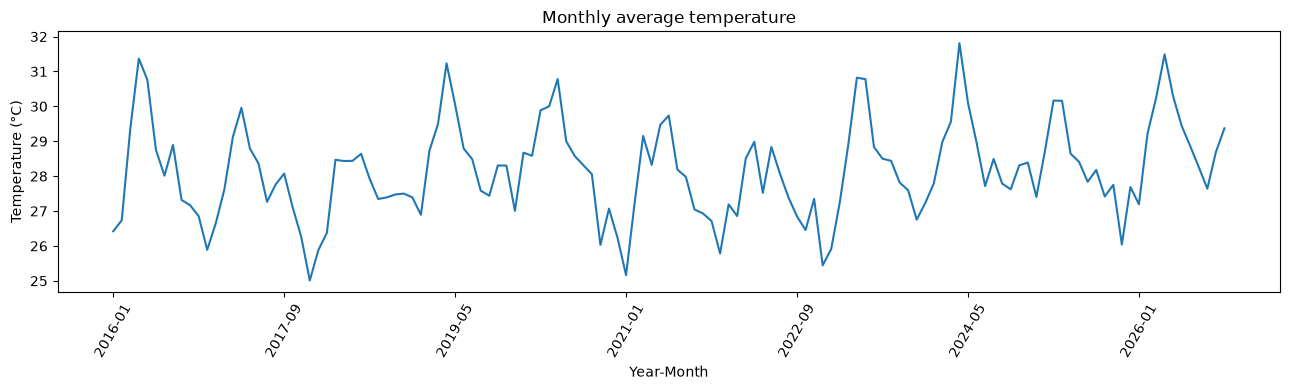

In [6]:
temp_monthly = (
    temperature.groupby(["year", "month"], as_index=False)
    .agg(
        avg_temp_c=("avg_temp", "mean"),
        min_temp_c=("avg_temp", "min"),
        max_temp_c=("avg_temp", "max"),
        observations=("avg_temp", "count"),
    )
    .sort_values(["year", "month"])
)

temp_yearly = (
    temperature.groupby("year", as_index=False)
    .agg(
        avg_temp_c=("avg_temp", "mean"),
        min_temp_c=("avg_temp", "min"),
        max_temp_c=("avg_temp", "max"),
        observations=("avg_temp", "count"),
    )
    .sort_values("year")
)

display(temp_monthly.head(12))
display(temp_yearly)

monthly_plot = temp_monthly.copy()
monthly_plot["period"] = (
    monthly_plot["year"].astype(str)
    + "-"
    + monthly_plot["month"].astype(str).str.zfill(2)
)

ax = monthly_plot.plot(
    x="period", y="avg_temp_c", figsize=(13, 4), legend=False
)
ax.set_title("Monthly average temperature")
ax.set_xlabel("Year-Month")
ax.set_ylabel("Temperature (°C)")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()


## 7. Electricity analysis — District และ Year

วิเคราะห์ปริมาณการใช้ไฟฟ้ารายเขตและรายปี ใช้หน่วยตามคอลัมน์ `consumption_million_kwh`


,year,total_million_kwh,mean_district_million_kwh,districts
0,2016,51375.48,2854.193333,18
1,2017,51182.91,2843.495000,18
2,2018,51600.21,2866.678333,18
3,2019,53304.37,2961.353889,18
4,2020,50661.82,2814.545556,18
5,2021,49560.75,2753.375000,18
6,2022,51484.32,2860.240000,18
7,2023,53890.80,2993.933333,18
8,2024,56536.30,3140.905556,18
9,2025,54435.21,3024.178333,18


District consumption in latest available year: 2025


,year,district,consumption_million_kwh
69,2025,บางพลี,5506.98
19,2025,คลองเตย,4816.83
59,2025,สมุทรปราการ,4751.15
89,2025,นนทบุรี,3747.15
79,2025,สามเสน,3725.44
119,2025,ราษฎร์บูรณะ,3660.49
139,2025,บางเขน,3434.25
39,2025,บางกะปิ,3368.96
149,2025,บางนา,3055.30
129,2025,บางขุนเทียน,2532.17


D:\Temp\ipykernel_13868\2553142982.py:36: UserWarning: Glyph 3610 (\N{THAI CHARACTER BO BAIMAI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
D:\Temp\ipykernel_13868\2553142982.py:36: UserWarning: Glyph 3634 (\N{THAI CHARACTER SARA AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
D:\Temp\ipykernel_13868\2553142982.py:36: UserWarning: Glyph 3591 (\N{THAI CHARACTER NGO NGU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
D:\Temp\ipykernel_13868\2553142982.py:36: UserWarning: Glyph 3651 (\N{THAI CHARACTER SARA AI MAIMUAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
D:\Temp\ipykernel_13868\2553142982.py:36: UserWarning: Glyph 3627 (\N{THAI CHARACTER HO HIP}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
D:\Temp\ipykernel_13868\2553142982.py:36: UserWarning: Glyph 3597 (\N{THAI CHARACTER YO YING}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
D:\Temp\ipykernel_13868\2553142982.py:36: UserWarning: Glyph 3621 (\N{THAI CHARACTER LO LIN

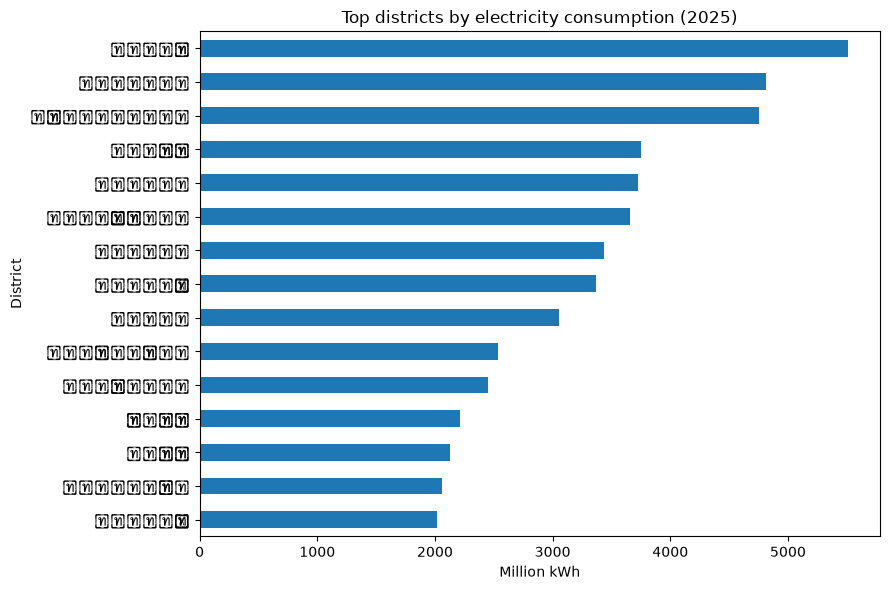

In [7]:
elec_yearly = (
    electricity.groupby("year", as_index=False)
    .agg(
        total_million_kwh=("consumption_million_kwh", "sum"),
        mean_district_million_kwh=("consumption_million_kwh", "mean"),
        districts=("district", "nunique"),
    )
    .sort_values("year")
)

display(elec_yearly)

latest_year = int(electricity["year"].max())
elec_latest = (
    electricity[electricity["year"] == latest_year]
    .sort_values("consumption_million_kwh", ascending=False)
)

print("District consumption in latest available year:", latest_year)
display(elec_latest.head(15))

ax = (
    elec_latest.head(15)
    .sort_values("consumption_million_kwh")
    .plot(
        kind="barh",
        x="district",
        y="consumption_million_kwh",
        figsize=(9, 6),
        legend=False,
    )
)
ax.set_title(f"Top districts by electricity consumption ({latest_year})")
ax.set_xlabel("Million kWh")
ax.set_ylabel("District")
plt.tight_layout()
plt.show()


## 8. Outlier screening ด้วย IQR

IQR ใช้ flag ค่าที่ควรตรวจสอบ ไม่ได้หมายความว่าค่านั้นผิดเสมอไป และ Notebook จะไม่ลบแถวที่ถูก flag อัตโนมัติ


In [8]:
def iqr_outlier_report(series: pd.Series, label: str):
    valid = series.dropna()
    q1 = valid.quantile(0.25)
    q3 = valid.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (series < lower) | (series > upper)

    print(
        f"{label}: lower={lower:.3f}, upper={upper:.3f}, "
        f"flagged={int(mask.sum())}"
    )
    return mask

temp_outlier_mask = iqr_outlier_report(
    temperature["avg_temp"], "Temperature (°C)"
)
elec_outlier_mask = iqr_outlier_report(
    electricity["consumption_million_kwh"], "Electricity (million kWh)"
)

display(temperature.loc[temp_outlier_mask].head(10))
display(electricity.loc[elec_outlier_mask].head(10))


Temperature (°C): lower=24.200, upper=32.200, flagged=130
Electricity (million kWh): lower=-606.825, upper=6258.195, flagged=0


,date,avg_temp,year,month
23,2016-01-24,21.6,2016,1
24,2016-01-25,17.2,2016,1
25,2016-01-26,19.3,2016,1
26,2016-01-27,21.6,2016,1
37,2016-02-07,21.3,2016,2
38,2016-02-08,20.4,2016,2
39,2016-02-09,22.2,2016,2
117,2016-04-27,32.4,2016,4
126,2016-05-06,32.4,2016,5
127,2016-05-07,32.6,2016,5


,year,district,consumption_million_kwh


## 9. Exploratory year-level comparison

ทดลองเปรียบเทียบค่าเฉลี่ยอุณหภูมิรายปีกับผลรวมการใช้ไฟฟ้าของเขตที่อยู่ในตาราง MEA โดยจับคู่ด้วย `year` เท่านั้น

**ข้อควรระวัง:** การเปรียบเทียบนี้เป็นเพียงภาพรวมตามเวลา ไม่ใช่การเชื่อมโยงรายเขตหรือรายครัวเรือน และอาจมีปัจจัยอื่น เช่น จำนวนผู้ใช้ไฟฟ้า การเติบโตของเมือง ฤดูกาล และการเปลี่ยนแปลงประชากร จึงห้ามสรุปเชิงเหตุและผลจาก correlation เพียงอย่างเดียว


,year,avg_temp_c,total_million_kwh,districts
0,2016,28.129781,51375.48,18
1,2017,27.658356,51182.91,18
2,2018,27.610959,51600.21,18
3,2019,28.520548,53304.37,18
4,2020,28.431967,50661.82,18
5,2021,27.642740,49560.75,18
6,2022,27.453151,51484.32,18
7,2023,28.241096,53890.80,18
8,2024,28.787978,56536.30,18
9,2025,28.198356,54435.21,18


Pearson correlation (year-level only): 0.687
Interpretation: ค่านี้เป็นความสัมพันธ์เชิงสำรวจระดับปีเท่านั้น ไม่ใช่หลักฐานว่าอุณหภูมิทำให้การใช้ไฟฟ้าเพิ่มขึ้น


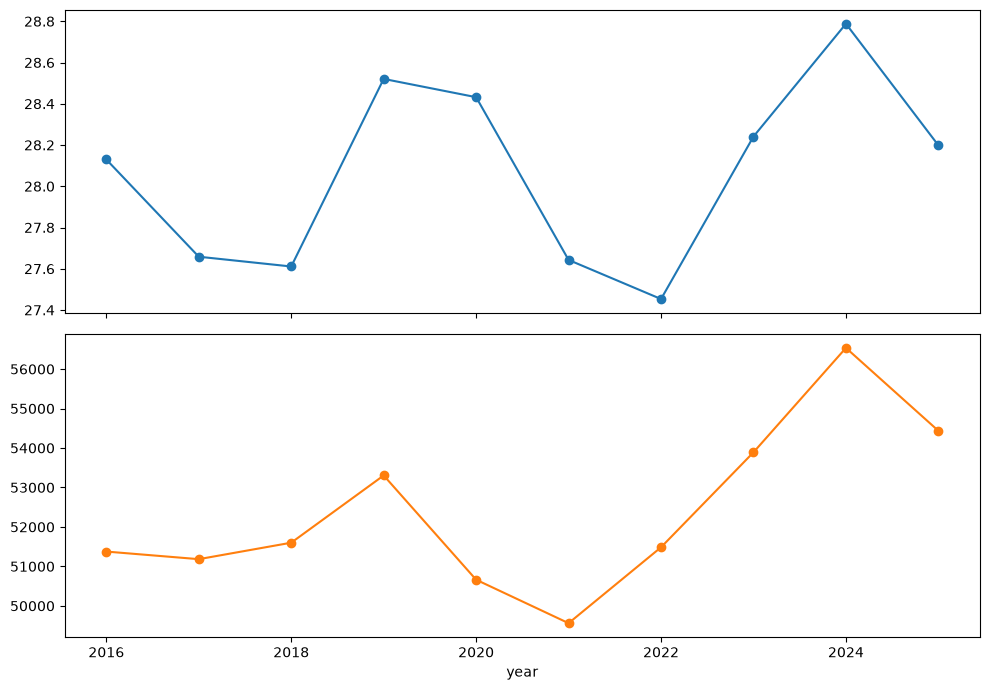

In [9]:
annual_comparison = temp_yearly[["year", "avg_temp_c"]].merge(
    elec_yearly[["year", "total_million_kwh", "districts"]],
    on="year",
    how="inner",
).sort_values("year")

display(annual_comparison)

if len(annual_comparison) >= 3:
    correlation = annual_comparison[
        ["avg_temp_c", "total_million_kwh"]
    ].corr().iloc[0, 1]
    print(f"Pearson correlation (year-level only): {correlation:.3f}")
    print(
        "Interpretation: ค่านี้เป็นความสัมพันธ์เชิงสำรวจระดับปีเท่านั้น "
        "ไม่ใช่หลักฐานว่าอุณหภูมิทำให้การใช้ไฟฟ้าเพิ่มขึ้น"
    )
else:
    print(
        "จำนวนปีที่จับคู่กันน้อยกว่า 3 ปี "
        "จึงไม่คำนวณ correlation"
    )

if not annual_comparison.empty:
    ax = annual_comparison.plot(
        x="year",
        y=["avg_temp_c", "total_million_kwh"],
        subplots=True,
        figsize=(10, 7),
        legend=False,
        marker="o",
    )
    plt.tight_layout()
    plt.show()


## 10. DuckDB analytical queries

Query จาก Parquet โดยตรงด้วย DuckDB เพื่อแสดงการใช้ analytical SQL แบบ local-first โดยไม่ต้องติดตั้ง Database Server


In [10]:
con = duckdb.connect(database=":memory:")

# สร้าง views จาก Parquet โดยตรง
con.from_parquet(TEMP_PATH.as_posix()).create_view("temperature")
con.from_parquet(ELEC_PATH.as_posix()).create_view("electricity")

print("Temperature yearly summary (DuckDB)")
display(con.execute(
    '''
    SELECT
        year,
        ROUND(AVG(avg_temp), 2) AS mean_temp_c,
        ROUND(MIN(avg_temp), 2) AS min_temp_c,
        ROUND(MAX(avg_temp), 2) AS max_temp_c,
        COUNT(*) AS observations
    FROM temperature
    GROUP BY year
    ORDER BY year
    '''
).df())

print("Electricity by year and district (DuckDB)")
display(con.execute(
    '''
    SELECT
        year,
        district,
        ROUND(consumption_million_kwh, 3) AS consumption_million_kwh
    FROM electricity
    ORDER BY year, consumption_million_kwh DESC
    LIMIT 20
    '''
).df())


Temperature yearly summary (DuckDB)


,year,mean_temp_c,min_temp_c,max_temp_c,observations
0,2016,28.13,17.2,33.1,366
1,2017,27.66,19.2,32.2,365
2,2018,27.61,21.1,31.2,365
3,2019,28.52,21.9,33.3,365
4,2020,28.43,22.0,32.2,366
5,2021,27.64,20.0,32.2,365
6,2022,27.45,21.9,31.6,365
7,2023,28.24,22.5,33.3,365
8,2024,28.79,25.4,33.2,366
9,2025,28.20,22.7,32.8,365


Electricity by year and district (DuckDB)


,year,district,consumption_million_kwh
0,2016,สมุทรปราการ,5292.95
1,2016,บางพลี,4820.80
2,2016,คลองเตย,4633.96
3,2016,ราษฎร์บูรณะ,3974.83
4,2016,สามเสน,3676.27
5,2016,นนทบุรี,3490.17
6,2016,บางเขน,3081.18
7,2016,บางกะปิ,2965.44
8,2016,บางนา,2618.82
9,2016,บางขุนเทียน,2541.34


## 11. Answers to project questions — checkpoint status

| คำถามใน Proposal | ข้อมูลที่มีใน Repository ขณะนี้ | สถานะ |
|---|---|---|
| Q1: วัสดุหลังคา/การระบายอากาศ/ร่มเงาเกี่ยวข้องกับผลกระทบจากความร้อนอย่างไร | มีอุณหภูมิรายวัน แต่ไม่มีตัวแปรลักษณะบ้านและผลกระทบความร้อนระดับครัวเรือน | ยังตอบไม่ได้ |
| Q2: รายได้เกี่ยวข้องกับค่าใช้จ่ายพลังงานและข้อจำกัดการรับมือความร้อนอย่างไร | มีการใช้ไฟฟ้าระดับเขต/ปี แต่ไม่มีรายได้และค่าใช้จ่ายพลังงานรายครัวเรือน | ตอบได้เพียงภาพรวมบางส่วน |

**ข้อเสนอสำหรับขั้นถัดไป**
1. รอ `03_transform.py` สร้าง Curated Data ใน Gold Zone และตรวจ schema จริงก่อนเพิ่ม Gold query
2. ตรวจว่ามี Key พื้นที่ที่สอดคล้องกันระหว่างข้อมูลอุณหภูมิกับข้อมูลการใช้ไฟฟ้าหรือไม่
3. หากต้องการตอบ Q1/Q2 ตาม Proposal ต้องเพิ่มข้อมูลลักษณะที่อยู่อาศัย รายได้ และ/หรือค่าใช้จ่ายพลังงานจากแหล่งสำรวจที่เหมาะสม
4. ระบุข้อจำกัดเรื่อง Spatial/Temporal granularity และ ecological fallacy ในการนำเสนอ


## 12. Checkpoint findings — บันทึกผลหลัง Run All

หลังรัน Notebook ทุก cell ให้เติมผลลัพธ์ที่ได้จริงจากหน้าจอ เช่น

- จำนวนแถวและช่วงปีของ Temperature
- จำนวนแถวและจำนวนเขตของ Electricity
- ค่าเฉลี่ย/ช่วงอุณหภูมิและการใช้ไฟฟ้า
- จำนวน Missing values, duplicates และ outliers ที่ถูก flag
- จำนวนปีที่สามารถจับคู่เพื่อดูภาพรวมเชิงเวลาได้

**อย่าใส่ค่าคาดเดาแทนผลลัพธ์จริง** และเก็บไฟล์ Notebook หลังรันพร้อม output ไว้เป็นหลักฐานสำหรับ Checkpoint Demo


## 10. Gold Zone EDA — Curated Data Analysis

ส่วนนี้เป็นการวิเคราะห์ข้อมูลจาก Gold Zone ซึ่งผ่านกระบวนการ Ingest, Validation และ Transformation มาแล้ว โดยใช้ Pandas และ DuckDB เพื่อสำรวจข้อมูลด้านอุณหภูมิและการใช้พลังงานในระดับเขตและรายปี

In [4]:
# Load Gold Zone datasets
GOLD_TABLES = {
    "temperature_monthly": "agg_temperature_monthly.parquet",
    "temperature_yearly": "agg_temperature_yearly.parquet",
    "year_energy_heat": "agg_year_energy_heat.parquet",
    "district": "dim_district.parquet",
    "district_energy_heat": "fact_district_energy_heat_yearly.parquet",
}

gold_data = {}

for name, filename in GOLD_TABLES.items():
    path = GOLD_DIR / filename
    gold_data[name] = pd.read_parquet(path)

    print(f"\n{'='*60}")
    print(f"Dataset: {name}")
    print(f"Shape: {gold_data[name].shape}")
    print("Columns:", gold_data[name].columns.tolist())
    display(gold_data[name].head(3))


Dataset: temperature_monthly
Shape: (131, 11)
Columns: ['station_id', 'year', 'month', 'n_days', 'days_in_month', 'completeness', 'is_complete_month', 'mean_temp_c', 'max_daily_mean_c', 'hot_days', 'cdd']


,station_id,year,month,n_days,days_in_month,completeness,is_complete_month,mean_temp_c,max_daily_mean_c,hot_days,cdd
0,OM_BKK_01,2016,1,31,31,1.0,True,26.42,28.6,0,91.3
1,OM_BKK_01,2016,2,29,29,1.0,True,26.73,28.7,0,87.4
2,OM_BKK_01,2016,3,31,31,1.0,True,29.35,30.8,9,166.0



Dataset: temperature_yearly
Shape: (11, 10)
Columns: ['station_id', 'year', 'n_days', 'days_in_year', 'completeness', 'is_complete_year', 'mean_temp_c', 'hottest_month_mean_c', 'hot_days', 'cdd']


,station_id,year,n_days,days_in_year,completeness,is_complete_year,mean_temp_c,hottest_month_mean_c,hot_days,cdd
0,OM_BKK_01,2016,366,366,1.0,True,28.13,31.37,65,1539.0
1,OM_BKK_01,2017,365,365,1.0,True,27.66,29.96,29,1362.6
2,OM_BKK_01,2018,365,365,1.0,True,27.61,28.64,12,1333.7



Dataset: year_energy_heat
Shape: (10, 10)
Columns: ['year', 'year_be', 'n_districts', 'total_consumption_million_kwh', 'mean_temp_c', 'hottest_month_mean_c', 'hot_days', 'cdd', 'covid_period', 'yoy_change_pct']


,year,year_be,n_districts,total_consumption_million_kwh,mean_temp_c,hottest_month_mean_c,hot_days,cdd,covid_period,yoy_change_pct
0,2016,2559,18,51375.48,28.13,31.37,65,1539.0,False,NaN
1,2017,2560,18,51182.91,27.66,29.96,29,1362.6,False,-0.37
2,2018,2561,18,51600.21,27.61,28.64,12,1333.7,False,0.82



Dataset: district
Shape: (18, 9)
Columns: ['district', 'district_en', 'former_name', 'province', 'lat', 'lon', 'station_id', 'station_name', 'distance_km']


,district,district_en,former_name,province,lat,lon,station_id,station_name,distance_km
0,บางบัวทอง,Bang Bua Thong,NaN,Nonthaburi,13.910,100.424,OM_BKK_01,Open-Meteo ERA5 grid cell - Bangkok,20.00
1,บางกะปิ,Bang Kapi,NaN,Bangkok,13.766,100.643,OM_BKK_01,Open-Meteo ERA5 grid cell - Bangkok,16.11
2,บางเขน,Bang Khen,NaN,Bangkok,13.873,100.596,OM_BKK_01,Open-Meteo ERA5 grid cell - Bangkok,17.97



Dataset: district_energy_heat
Shape: (180, 17)
Columns: ['year', 'year_be', 'district', 'district_en', 'province', 'station_id', 'station_distance_km', 'consumption_million_kwh', 'yoy_change_pct', 'index_first_year_100', 'share_of_total_pct', 'mean_temp_c', 'hottest_month_mean_c', 'hot_days', 'cdd', 'temp_completeness', 'covid_period']


,year,year_be,district,district_en,province,station_id,station_distance_km,consumption_million_kwh,yoy_change_pct,index_first_year_100,share_of_total_pct,mean_temp_c,hottest_month_mean_c,hot_days,cdd,temp_completeness,covid_period
0,2016,2559,บางบัวทอง,Bang Bua Thong,Nonthaburi,OM_BKK_01,20.0,1721.21,NaN,100.00,3.35,28.13,31.37,65,1539.0,1.0,False
1,2017,2560,บางบัวทอง,Bang Bua Thong,Nonthaburi,OM_BKK_01,20.0,1780.94,3.47,103.47,3.48,27.66,29.96,29,1362.6,1.0,False
2,2018,2561,บางบัวทอง,Bang Bua Thong,Nonthaburi,OM_BKK_01,20.0,1838.00,3.20,106.79,3.56,27.61,28.64,12,1333.7,1.0,False


In [5]:
# Top 10 districts by electricity consumption
district_energy = gold_data["district_energy_heat"]

latest_year = district_energy["year"].max()

top_districts = (
    district_energy[district_energy["year"] == latest_year]
    .sort_values("consumption_million_kwh", ascending=False)
    [["district", "district_en", "consumption_million_kwh",
      "mean_temp_c", "hot_days", "cdd"]]
    .head(10)
)

print("Latest year:", latest_year)
display(top_districts)

Latest year: 2025


,district,district_en,consumption_million_kwh,mean_temp_c,hot_days,cdd
59,บางพลี,Bang Phli,5506.98,28.2,46,1536.1
79,คลองเตย,Khlong Toei,4816.83,28.2,46,1536.1
149,สมุทรปราการ,Samut Prakan,4751.15,28.2,46,1536.1
109,นนทบุรี,Nonthaburi,3747.15,28.2,46,1536.1
139,สามเสน,Samsen,3725.44,28.2,46,1536.1
129,ราษฎร์บูรณะ,Rat Burana,3660.49,28.2,46,1536.1
29,บางเขน,Bang Khen,3434.25,28.2,46,1536.1
19,บางกะปิ,Bang Kapi,3368.96,28.2,46,1536.1
49,บางนา,Bang Na,3055.30,28.2,46,1536.1
39,บางขุนเทียน,Bang Khun Thian,2532.17,28.2,46,1536.1


In [12]:

# Query Gold Zone using DuckDB

gold_year_path = (GOLD_DIR / "agg_year_energy_heat.parquet").as_posix()

energy_trend = duckdb.sql(f"""
    SELECT
        year,
        total_consumption_million_kwh,
        mean_temp_c,
        hot_days,
        cdd,
        yoy_change_pct,
        covid_period
    FROM read_parquet('{gold_year_path}')
    ORDER BY year
""").df()

display(energy_trend)

,year,total_consumption_million_kwh,mean_temp_c,hot_days,cdd,yoy_change_pct,covid_period
0,2016,51375.48,28.13,65,1539.0,NaN,False
1,2017,51182.91,27.66,29,1362.6,-0.37,False
2,2018,51600.21,27.61,12,1333.7,0.82,False
3,2019,53304.37,28.52,54,1657.9,3.30,False
4,2020,50661.82,28.43,61,1628.6,-4.96,True
5,2021,49560.75,27.64,37,1347.8,-2.17,True
6,2022,51484.32,27.45,12,1269.0,3.88,False
7,2023,53890.80,28.24,53,1556.7,4.67,False
8,2024,56536.30,28.79,65,1752.4,4.91,False
9,2025,54435.21,28.20,46,1536.1,-3.72,False


In [13]:
# Correlation analysis: temperature vs electricity consumption

correlation = energy_trend[
    ["total_consumption_million_kwh", "mean_temp_c", "hot_days", "cdd"]
].corr()

display(correlation)

,total_consumption_million_kwh,mean_temp_c,hot_days,cdd
total_consumption_million_kwh,1.000000,0.688096,0.408445,0.666786
mean_temp_c,0.688096,1.000000,0.879530,0.998648
hot_days,0.408445,0.879530,1.000000,0.896355
cdd,0.666786,0.998648,0.896355,1.000000


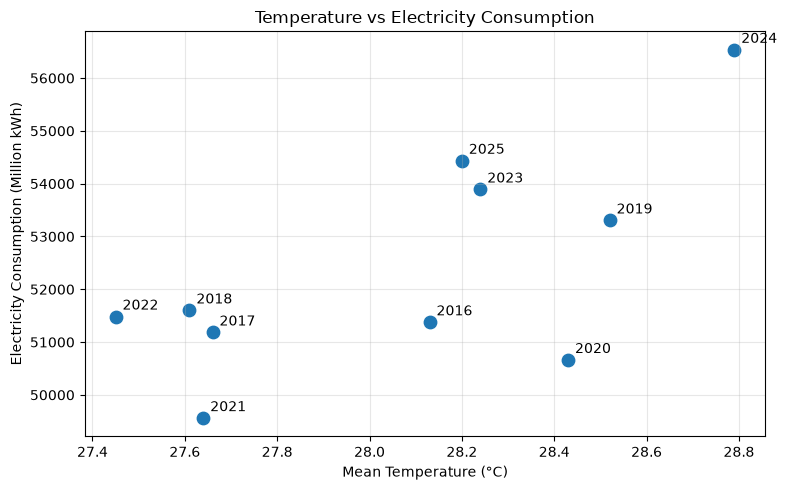

In [14]:
# Scatter plot: Temperature vs Electricity

plt.figure(figsize=(8, 5))

plt.scatter(
    energy_trend["mean_temp_c"],
    energy_trend["total_consumption_million_kwh"],
    s=80
)

for _, row in energy_trend.iterrows():
    plt.annotate(
        str(row["year"]),
        (row["mean_temp_c"], row["total_consumption_million_kwh"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Mean Temperature (°C)")
plt.ylabel("Electricity Consumption (Million kWh)")
plt.title("Temperature vs Electricity Consumption")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Gold Zone EDA — Key Findings

### 1. Electricity Consumption Trend
- Electricity consumption increased from 2016 to 2019.
- Consumption declined during 2020–2021.
- Consumption recovered during 2022–2024, reaching its highest value in 2024 (56,536.30 million kWh).
- Consumption decreased by 3.72% in 2025.

### 2. Temperature and Electricity Relationship
- Mean temperature has a positive correlation with electricity consumption (r = 0.688).
- CDD has a positive correlation with electricity consumption (r = 0.667).
- Hot days have a weaker positive correlation (r = 0.408).

### 3. Limitations
- The correlation analysis uses only 10 annual observations (2016–2025).
- Correlation does not imply causation.
- Temperature indicators come from a shared weather station and do not represent independent district-level measurements.
- Electricity consumption is aggregated at district/year level, not household level.
- Household income, housing characteristics, and individual electricity bills are unavailable.
- Therefore, the current data cannot directly establish household-level heat vulnerability or energy burden.